In [10]:
!pip install hdbscan

import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

visualize function

In [13]:
import matplotlib.pyplot as plt
import numpy as np


def plot(
    X,
    labels=None,
    probabilities=None,
    parameters=None,
    ground_truth=False,
    ax=None,
):
    # Fix 1: Pastikan X adalah NumPy array (menghindari InvalidIndexError dari pandas)
    if hasattr(X, "values"):
        X = X.values

    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))

    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = (
        probabilities if probabilities is not None else np.ones(X.shape[0])
    )

    unique_labels = set(labels)
    colors = [
        plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))
    ]

    # Iterasi per kluster
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # Warna hitam untuk noise

        # Ambil subset titik untuk kluster k
        mask = labels == k
        X_k = X[mask]
        prob_k = probabilities[mask]

        if k == -1:
            # Plot titik noise (x)
            ax.scatter(
                X_k[:, 0],
                X_k[:, 1],
                marker="x",
                c=[col],
                edgecolors="k",
                s=16,
                label="Noise",
            )
        else:
            # Plot titik kluster (o) dengan ukuran disesuaikan probabilitas
            sizes = (1 + 5 * prob_k) ** 2  # s pada scatter memakai kuadrat ukuran
            ax.scatter(
                X_k[:, 0],
                X_k[:, 1],
                marker="o",
                c=[col],
                edgecolors="k",
                s=sizes,
                label=f"Cluster {k}",
            )

    n_clusters_ = len(unique_labels) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"

    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"

    ax.set_title(title)
    plt.tight_layout()  # Fix 2: Menghapus huruf 'b' di akhir baris ini

## create synthetic data

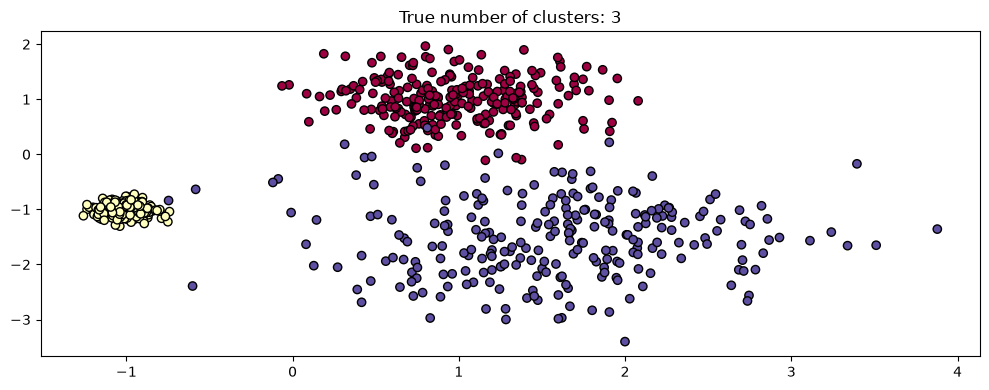

In [14]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
	n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
	)
	
plot(X, labels=labels_true, ground_truth=True)

## test Scale Invariance on the DBSCAN Model

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


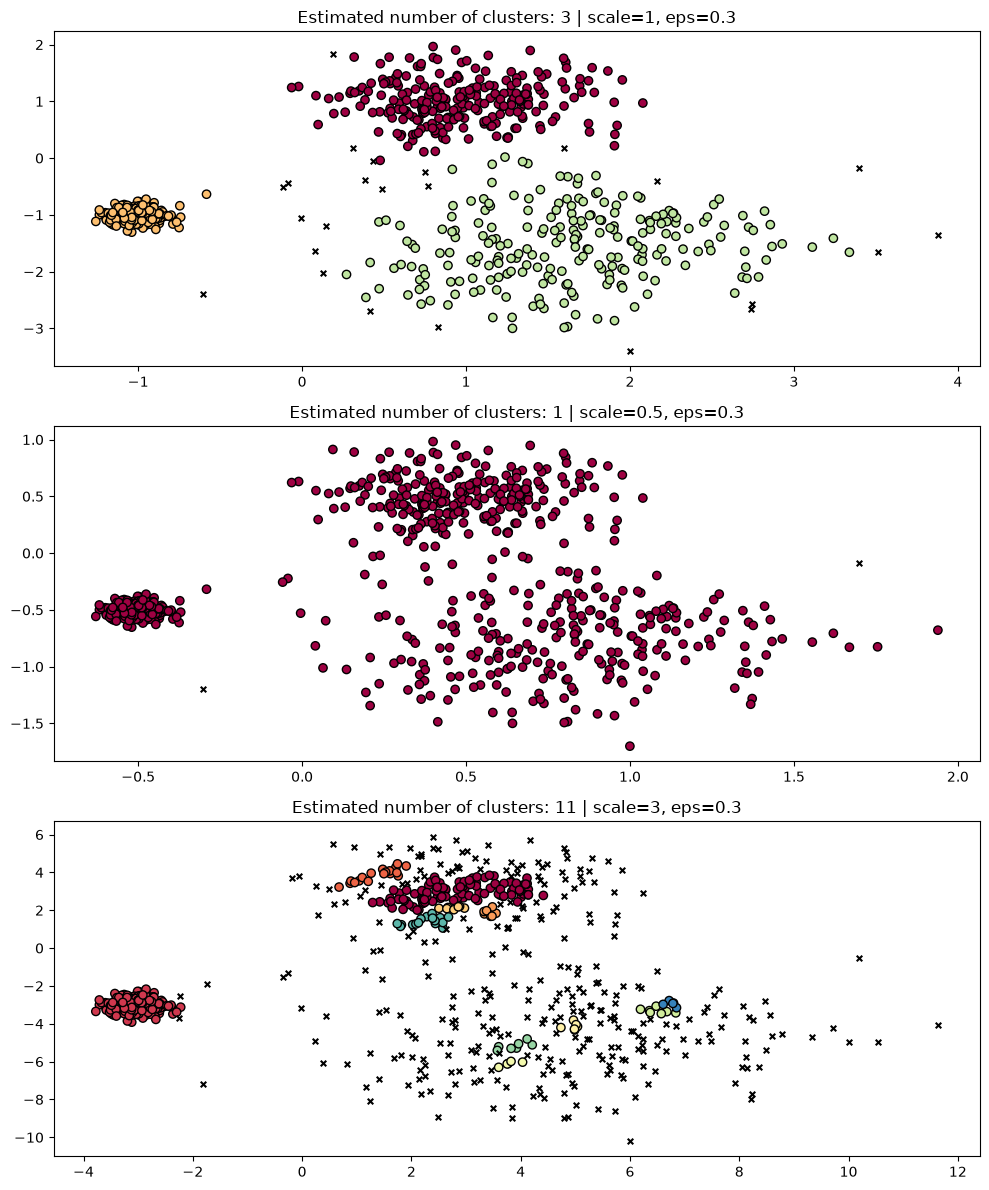

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
	dbs.fit(X * scale)
	plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


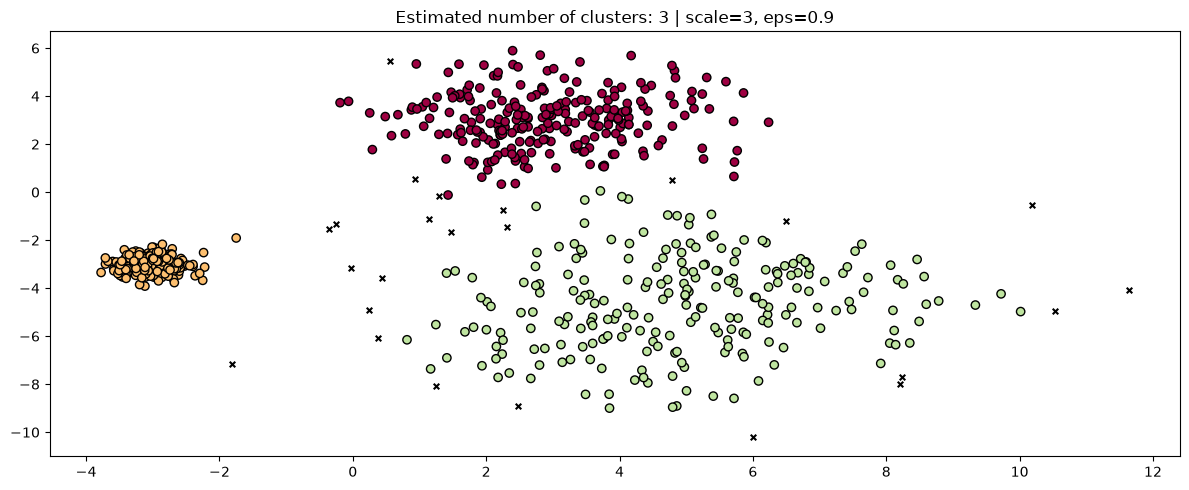

In [17]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

## Create HDBSCAN Model

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


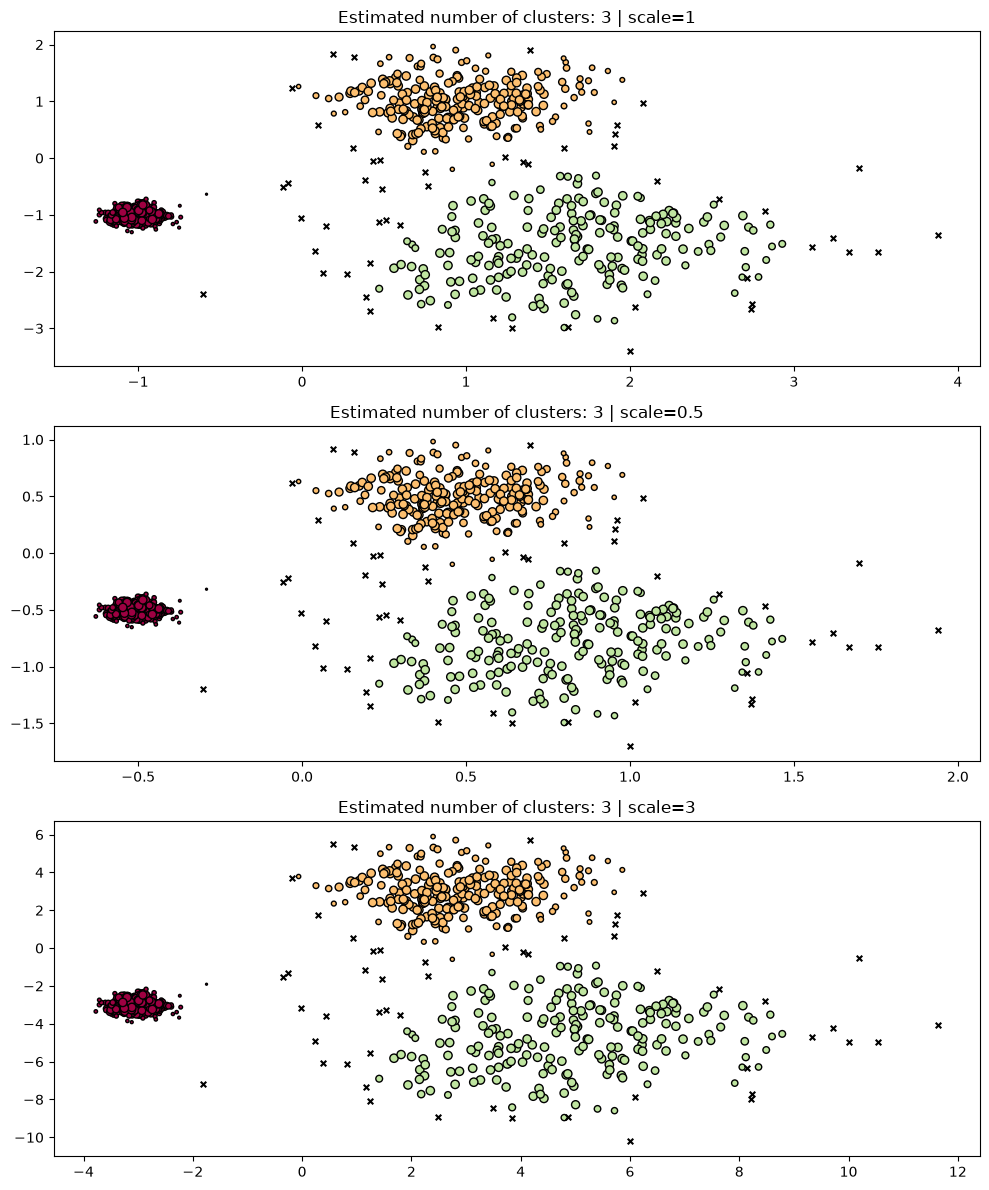

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
	hdb.fit(X * scale)
	plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

## Multiscale Clustering

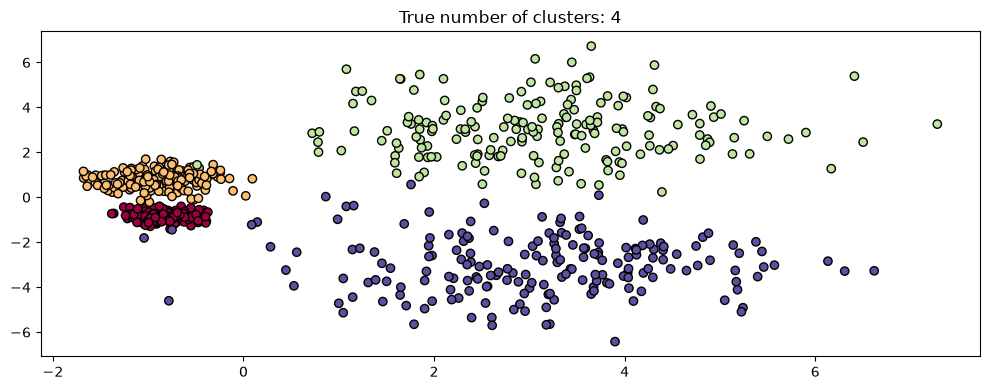

In [19]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
	n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
	)
plot(X, labels=labels_true, ground_truth=True)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


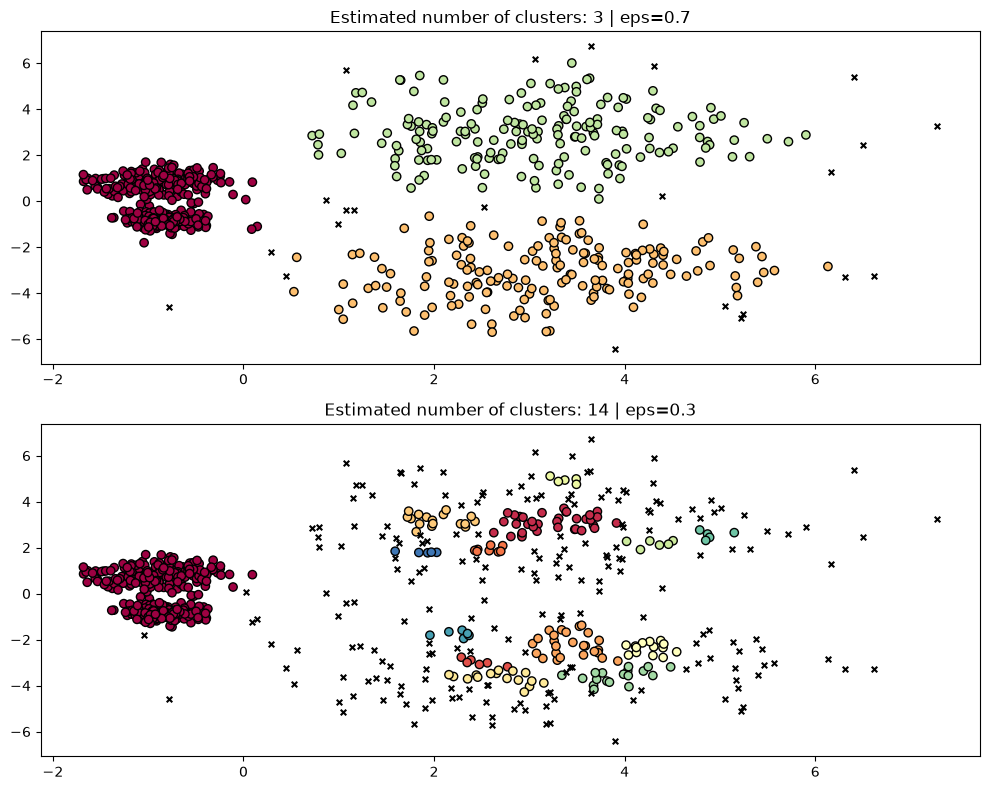

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])
	
params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_2560\3338294288.py:42: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


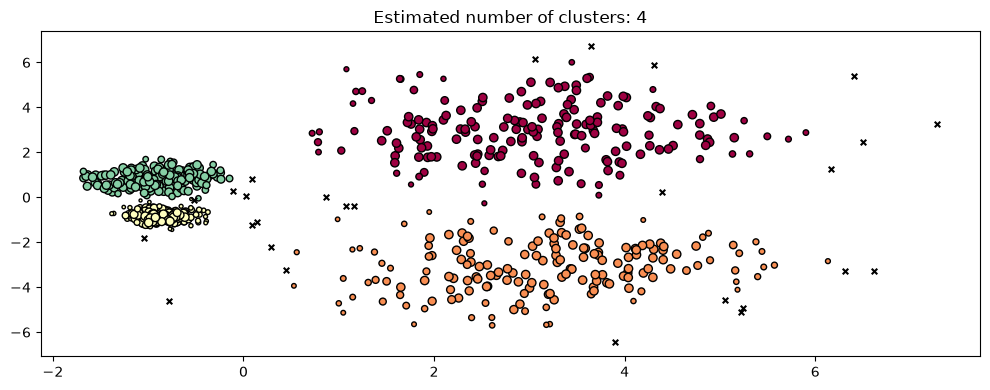

In [21]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)